
🪙 ETHUSDT | 1h | 01/01/2024 → 15/06/2026
⏳ Downloading ETHUSDT 1h...
✅ 21479 bars ready.
🚀 Running backtest...

🎯 SMMA(10)+RSI(10,Wilder)+KC(20,2.3)+AdaptiveVol+Fees+RSI Reversal Exit
      Final Equity: 14668.637171
      Total Return: 0.466864
     CAGR (approx): 0.169445
      Max Drawdown: -0.087942
            Sharpe: 1.522799
            Trades: 390
           Winrate: 0.687179
     Avg PnL/Trade: 11.970865
     Profit Factor: 1.353216

          Est. R:R: 1:0.62


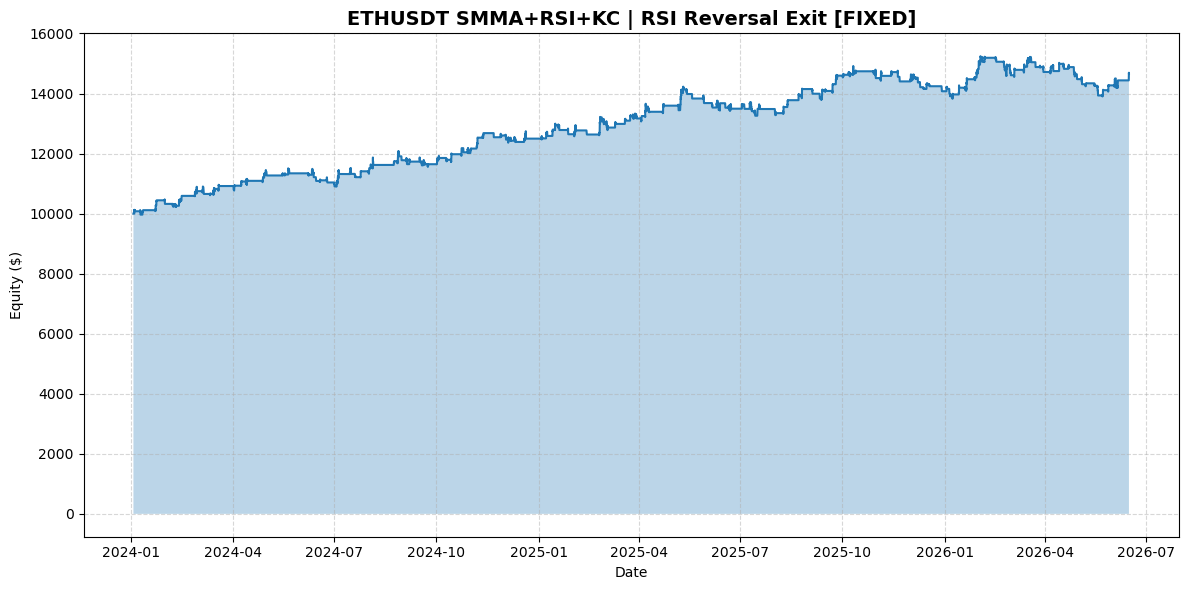


📊 Sample Trades (first 10):
            Exit Time   Type        Entry         Exit       Qty   PnL_gross  EntryFee   ExitFee   TotalFee     PnL_net     Reason       Balance
0 2024-01-03 14:00:00  SHORT  2248.550000  2192.347599  1.213545   68.204132  2.728716  2.660512   5.389228   62.814903        TP1  10060.086187
1 2024-01-04 04:00:00  SHORT  2248.550000  2231.070000  1.213545   21.212763  2.728716  2.707503   5.436220   15.776543  Time Exit  10078.591447
2 2024-01-09 00:00:00   LONG  2335.980000  2293.741945  2.386140 -100.785914  5.573975  5.473189  11.047165 -111.833079  Stop Loss   9966.758367
3 2024-01-10 23:00:00   LONG  2516.237437  2614.643149  0.651985   64.159080  1.640550  1.704709   3.345259   60.813822        TP1  10025.931639
4 2024-01-11 10:00:00   LONG  2516.237437  2647.445053  0.195596   25.663632  0.492165  0.517829   1.009994   24.653639        TP2  10051.077443
5 2024-01-11 12:00:00   LONG  2516.237437  2657.890000  0.456390   64.648775  1.148385  1.213034   2.

In [5]:
import requests
import pandas as pd
import numpy as np
from datetime import datetime
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# =========================================================
# 1) FETCH BINANCE DATA
# =========================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    url = "https://api.binance.com/api/v3/klines"
    start_time = str_to_millis(start_str)
    end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
    end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {symbol} {interval}...")
    while start_time < end_time:
        params = {"symbol": symbol.upper(), "interval": interval,
                  "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200:
                print("Error:", r.status_code, r.text); break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except Exception as e:
            print("Fetch error:", e); break

    if not all_klines:
        return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df


# =========================================================
# 2) INDICATORS
# =========================================================
def calculate_indicators(df: pd.DataFrame) -> pd.DataFrame:
    data = df.copy()

    prev_close = data["Close"].shift(1)
    tr = pd.concat([
        (data["High"] - data["Low"]),
        (data["High"] - prev_close).abs(),
        (data["Low"]  - prev_close).abs(),
    ], axis=1).max(axis=1)
    data["TR"] = tr

    def calc_atr(tr_series: pd.Series, period: int) -> pd.Series:
        return tr_series.ewm(alpha=1/period, min_periods=period, adjust=False).mean()

    data["ATR_20"] = calc_atr(data["TR"], 20)
    data["ATR_30"] = calc_atr(data["TR"], 30)
    data["ATR_50"] = calc_atr(data["TR"], 50)

    # SMMA(10) = Wilder EMA
    data["SMMA_10_Close"] = data["Close"].ewm(alpha=1/10, min_periods=10, adjust=False).mean()

    # FIX 1: RSI Wilder EMA (matches TradingView / SQX)
    # Code gốc dùng rolling().mean() → RSI-SMA, không match platform
    def calc_rsi_wilder(series: pd.Series, period: int) -> pd.Series:
        delta = series.diff()
        gain  = delta.where(delta > 0, 0.0).ewm(alpha=1/period, min_periods=period, adjust=False).mean()
        loss  = (-delta.where(delta < 0, 0.0)).ewm(alpha=1/period, min_periods=period, adjust=False).mean()
        rs    = gain / loss
        return 100 - (100 / (1 + rs))

    data["RSI_10_Close"] = calc_rsi_wilder(data["Close"], 10)

    # KC(20, dev=2.3) — Wilder EMA nhất quán cho cả center và bandwidth
    # FIX 2: code gốc dùng ewm(span=20) cho center (alpha≈0.095)
    #        nhưng Wilder ATR dùng alpha=1/20=0.05 → mixed convention
    #        Sửa về Wilder EMA cho nhất quán
    ema_20_kc = data["Close"].ewm(alpha=1/20, min_periods=20, adjust=False).mean()
    data["KC_Upper_20_2p3"] = ema_20_kc + 2.3 * data["ATR_20"]
    data["KC_Lower_20_2p3"] = ema_20_kc - 2.3 * data["ATR_20"]

    data["Highest_Close_25"] = data["Close"].rolling(window=25).max()
    data["Lowest_Close_25"]  = data["Close"].rolling(window=25).min()

    # ── Parabolic SAR ────────────────────────────────────────
    # Convention: psar_trend = +1 (bullish, SAR below price)
    #             psar_trend = -1 (bearish, SAR above price)
    # Dùng AF mặc định: step=0.02, max=0.20
    psar_af_step = 0.02
    psar_af_max  = 0.20

    closes = data["Close"].values
    highs  = data["High"].values
    lows   = data["Low"].values
    n_bars = len(data)

    psar_arr  = np.full(n_bars, np.nan)
    trend_arr = np.zeros(n_bars, dtype=int)

    # Khởi tạo từ bar thứ 2
    trend_arr[0] = 1
    psar_arr[0]  = lows[0]
    ep           = highs[0]
    af           = psar_af_step

    for k in range(1, n_bars):
        prev_psar  = psar_arr[k-1]
        prev_trend = trend_arr[k-1]

        if prev_trend == 1:  # bullish
            new_psar = prev_psar + af * (ep - prev_psar)
            new_psar = min(new_psar, lows[k-1])
            if k >= 2:
                new_psar = min(new_psar, lows[k-2])

            if lows[k] < new_psar:  # reversal → bearish
                trend_arr[k] = -1
                psar_arr[k]  = ep
                ep = lows[k]
                af = psar_af_step
            else:
                trend_arr[k] = 1
                psar_arr[k]  = new_psar
                if highs[k] > ep:
                    ep = highs[k]
                    af = min(af + psar_af_step, psar_af_max)
        else:  # bearish
            new_psar = prev_psar + af * (ep - prev_psar)
            new_psar = max(new_psar, highs[k-1])
            if k >= 2:
                new_psar = max(new_psar, highs[k-2])

            if highs[k] > new_psar:  # reversal → bullish
                trend_arr[k] = 1
                psar_arr[k]  = ep
                ep = highs[k]
                af = psar_af_step
            else:
                trend_arr[k] = -1
                psar_arr[k]  = new_psar
                if lows[k] < ep:
                    ep = lows[k]
                    af = min(af + psar_af_step, psar_af_max)

    data["PSAR"]       = psar_arr
    data["PSAR_Trend"] = trend_arr  # +1 bullish, -1 bearish

    # ── MACD Histogram ───────────────────────────────────────
    # MACD Line  = EMA(fast) - EMA(slow)
    # Signal Line = EMA(MACD, signal_period)
    # Histogram   = MACD Line - Signal Line
    # Đổi dấu histogram (+ → -) = momentum đảo chiều, detect sớm hơn giá cắt SMMA
    macd_fast   = 7
    macd_slow   = 14
    macd_signal = 9
    ema_fast            = data["Close"].ewm(span=macd_fast,   adjust=False).mean()
    ema_slow            = data["Close"].ewm(span=macd_slow,   adjust=False).mean()
    data["MACD_Line"]   = ema_fast - ema_slow
    data["MACD_Signal"] = data["MACD_Line"].ewm(span=macd_signal, adjust=False).mean()
    data["MACD_Hist"]   = data["MACD_Line"] - data["MACD_Signal"]

    data.dropna(inplace=True)
    return data


# =========================================================
# 3) BACKTESTER
# =========================================================
class SMMA_RSI_KC_Breakout_Backtester:
    def __init__(self, df: pd.DataFrame, initial_balance: float = 10000.0):
        self.df = df
        self.initial_balance = float(initial_balance)
        self.balance = float(initial_balance)

        self.equity_curve = []
        self.trades = []

        self.position      = None
        self.entry_price   = 0.0
        self.sl            = 0.0
        self.tp            = 0.0
        self.qty           = 0.0
        self.entry_bar_idx = 0
        self.pending_order = None

        # Entry / Exit
        self.price_entry_mult   = 2.4
        self.exit_after_bars    = 14
        self.pending_expiration = 4
        self.sl_coef            = 2.1
        self.tp_coef            = 4.5

        # MM
        self.risk_pct = 0.02

        # Fees
        self.fee_rate        = 0.001
        self._last_entry_fee = 0.0

        # Adaptive Vol Filter
        self.vol_ratio_min_base       = 1.05
        self.vol_ratio_min_trend      = 1.00
        self.trend_strength_threshold = 0.60

        # ── Multi-TP (ATR-based, partial close) ──────────────
        # TP1 = entry ± tp1_atr_mult × ATR  → đóng tp1_ratio (50%)
        # TP2 = entry ± tp2_atr_mult × ATR  → đóng tp2_ratio (30%)
        # TP3 = entry ± tp3_atr_mult × ATR  → đóng nốt (20%)
        self.tp1_atr_mult = 2.0
        self.tp2_atr_mult = 3.5
        self.tp3_atr_mult = 5.0
        self.tp1_ratio    = 0.50   # đóng 50% tại TP1
        self.tp2_ratio    = 0.30   # đóng 30% tại TP2
        # tp3_ratio = 1 - tp1 - tp2 = 20% (đóng hết phần còn lại)

        # Internal TP state (reset mỗi lần mở lệnh)
        self.tp1 = 0.0; self.tp1_hit = False
        self.tp2 = 0.0; self.tp2_hit = False
        self.tp3 = 0.0
        # tp cũ giữ lại làm tp3 để tương thích các exit khác
        self.tp  = 0.0

        # Parabolic SAR exit (Hướng 4)
        self.use_psar_exit  = True

        # MACD Histogram đổi dấu exit (Hướng 1)
        self.use_macd_exit  = False

    def run(self):
        idxs = self.df.index
        n    = len(self.df)

        for i in range(n):
            bar = self.df.iloc[i]
            t   = idxs[i]

            # ── A) Manage open position ───────────────────────
            if self.position is not None:
                held = i - self.entry_bar_idx

                # FIX 3: Time exit → Open[i+1], không phải Close[i]
                if held >= self.exit_after_bars:
                    if i + 1 < n:
                        exit_px, exit_t = self.df.iloc[i+1]["Open"], idxs[i+1]
                    else:
                        exit_px, exit_t = bar["Close"], t   # edge: bar cuối
                    self.close_position(exit_px, exit_t, "Time Exit")
                    self.append_equity(t); continue

                # Parabolic SAR exit (Hướng 4)
                # SAR đổi từ bullish (+1) sang bearish (-1) → thoát LONG sớm
                # SAR đổi từ bearish (-1) sang bullish (+1) → thoát SHORT sớm
                # Dùng shift=1 (closed bar) → không look-ahead
                # Exit tại Open[i+1]
                if self.use_psar_exit and i >= 2:
                    psar_trend_1 = int(self.df.iloc[i-1]["PSAR_Trend"])  # trend SAU bar i-1
                    psar_trend_2 = int(self.df.iloc[i-2]["PSAR_Trend"])  # trend SAU bar i-2

                    # PSAR đổi chiều: bullish → bearish (i-2=+1, i-1=-1) → thoát LONG
                    exit_long_psar  = (self.position == "LONG"
                                       and psar_trend_2 == 1 and psar_trend_1 == -1)
                    # PSAR đổi chiều: bearish → bullish (i-2=-1, i-1=+1) → thoát SHORT
                    exit_short_psar = (self.position == "SHORT"
                                       and psar_trend_2 == -1 and psar_trend_1 == 1)

                    if exit_long_psar or exit_short_psar:
                        if i + 1 < n:
                            exit_px, exit_t = self.df.iloc[i+1]["Open"], idxs[i+1]
                        else:
                            exit_px, exit_t = bar["Close"], t
                        self.close_position(exit_px, exit_t, "PSAR Reversal")
                        self.append_equity(t); continue

                # MACD Histogram đổi dấu exit (Hướng 1)
                # hist[i-2] >= 0 AND hist[i-1] < 0 → vừa đổi dương→âm → thoát LONG
                # hist[i-2] <= 0 AND hist[i-1] > 0 → vừa đổi âm→dương → thoát SHORT
                # Detect momentum đảo chiều sớm hơn giá cắt SMMA
                if self.use_macd_exit and i >= 2:
                    hist_1 = self.df.iloc[i-1]["MACD_Hist"]
                    hist_2 = self.df.iloc[i-2]["MACD_Hist"]

                    exit_long_macd  = (self.position == "LONG"
                                       and hist_2 >= 0 and hist_1 < 0)
                    exit_short_macd = (self.position == "SHORT"
                                       and hist_2 <= 0 and hist_1 > 0)

                    if exit_long_macd or exit_short_macd:
                        if i + 1 < n:
                            exit_px, exit_t = self.df.iloc[i+1]["Open"], idxs[i+1]
                        else:
                            exit_px, exit_t = bar["Close"], t
                        self.close_position(exit_px, exit_t, "MACD Reversal")
                        self.append_equity(t); continue

                # SL — đóng toàn bộ
                if self.position == "LONG":
                    if bar["Low"] <= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t); continue

                elif self.position == "SHORT":
                    if bar["High"] >= self.sl:
                        self.close_position(self.sl, t, "Stop Loss")
                        self.append_equity(t); continue

                # Multi-TP partial close — check theo thứ tự TP1 → TP2 → TP3
                if self.position == "LONG":
                    if not self.tp1_hit and bar["High"] >= self.tp1:
                        self.partial_close(self.tp1, t, "TP1", self.tp1_ratio)
                        self.tp1_hit = True
                    elif self.tp1_hit and not self.tp2_hit and bar["High"] >= self.tp2:
                        self.partial_close(self.tp2, t, "TP2", self.tp2_ratio)
                        self.tp2_hit = True
                    elif self.tp1_hit and self.tp2_hit and bar["High"] >= self.tp3:
                        self.close_position(self.tp3, t, "TP3")
                        self.append_equity(t); continue

                elif self.position == "SHORT":
                    if not self.tp1_hit and bar["Low"] <= self.tp1:
                        self.partial_close(self.tp1, t, "TP1", self.tp1_ratio)
                        self.tp1_hit = True
                    elif self.tp1_hit and not self.tp2_hit and bar["Low"] <= self.tp2:
                        self.partial_close(self.tp2, t, "TP2", self.tp2_ratio)
                        self.tp2_hit = True
                    elif self.tp1_hit and self.tp2_hit and bar["Low"] <= self.tp3:
                        self.close_position(self.tp3, t, "TP3")
                        self.append_equity(t); continue

            # ── B) Pending order ──────────────────────────────
            if self.position is None and self.pending_order is not None:
                if i >= self.pending_order["expire_idx"]:
                    self.pending_order = None
                else:
                    p = self.pending_order["price"]
                    if self.pending_order["type"] == "BUY_STOP" and bar["High"] >= p:
                        self.open_position("LONG", max(p, bar["Open"]), i,
                                           self.pending_order["sl_dist"],
                                           self.pending_order["tp_dist"])
                        self.pending_order = None
                    elif self.pending_order["type"] == "SELL_STOP" and bar["Low"] <= p:
                        self.open_position("SHORT", min(p, bar["Open"]), i,
                                           self.pending_order["sl_dist"],
                                           self.pending_order["tp_dist"])
                        self.pending_order = None

            # ── C) Signal → pending ───────────────────────────
            if self.position is None and self.pending_order is None:
                if i < 3:
                    self.append_equity(t); continue

                open_0   = bar["Open"]
                close_1  = self.df.iloc[i-1]["Close"]
                smma10_1 = self.df.iloc[i-1]["SMMA_10_Close"]
                atr20_1  = self.df.iloc[i-1]["ATR_20"]
                atr30_1  = self.df.iloc[i-1]["ATR_30"]
                atr50_1  = self.df.iloc[i-1]["ATR_50"]
                kc_up_1  = self.df.iloc[i-1]["KC_Upper_20_2p3"]
                kc_lo_1  = self.df.iloc[i-1]["KC_Lower_20_2p3"]
                rsi_2    = self.df.iloc[i-2]["RSI_10_Close"]
                rsi_1    = self.df.iloc[i-1]["RSI_10_Close"]

                vol_ratio      = (atr20_1 / atr50_1) if atr50_1 > 0 else 0.0
                trend_strength = (abs(close_1 - smma10_1) / atr20_1) if atr20_1 > 0 else 0.0
                vol_min = (self.vol_ratio_min_trend
                           if trend_strength >= self.trend_strength_threshold
                           else self.vol_ratio_min_base)
                vol_ok = vol_ratio >= vol_min

                long_signal  = vol_ok and (close_1 > smma10_1) and (rsi_2 < rsi_1) and (open_0 > kc_up_1)
                short_signal = vol_ok and (close_1 < smma10_1) and (rsi_2 > rsi_1) and (open_0 < kc_lo_1)

                if (not long_signal) and (not short_signal):
                    self.append_equity(t); continue

                highest_3 = self.df.iloc[i-3]["Highest_Close_25"]
                lowest_3  = self.df.iloc[i-3]["Lowest_Close_25"]
                atr50_3   = self.df.iloc[i-3]["ATR_50"]
                sl_dist   = self.sl_coef * atr20_1
                tp_dist   = self.tp_coef * atr30_1

                if long_signal:
                    entry = highest_3 + self.price_entry_mult * atr50_3
                    self.pending_order = {"type": "BUY_STOP",  "price": float(entry),
                                          "sl_dist": float(sl_dist), "tp_dist": float(tp_dist),
                                          "expire_idx": i + self.pending_expiration}
                elif short_signal:
                    entry = lowest_3 - self.price_entry_mult * atr50_3
                    self.pending_order = {"type": "SELL_STOP", "price": float(entry),
                                          "sl_dist": float(sl_dist), "tp_dist": float(tp_dist),
                                          "expire_idx": i + self.pending_expiration}

            # ── D) Equity ─────────────────────────────────────
            self.append_equity(t)

    def open_position(self, pos_type: str, price: float, bar_idx: int,
                      sl_dist: float, tp_dist: float):
        self.position      = pos_type
        self.entry_price   = float(price)
        self.entry_bar_idx = int(bar_idx)
        self.sl = self.entry_price - sl_dist if pos_type == "LONG" else self.entry_price + sl_dist

        # ── Multi-TP levels (ATR-based) ───────────────────────
        # Dùng atr30 tại bar fill để tính TP — shift=1 đã được truyền vào sl_dist/tp_dist
        # tp_dist (= tp_coef × ATR30) là 1 ATR unit → dùng làm tham chiếu
        # Thực tế: tp_dist = 4.5 × ATR30, nên ATR30_ref = tp_dist / tp_coef
        atr30_ref = tp_dist / self.tp_coef   # ATR30 tại lúc mở lệnh

        if pos_type == "LONG":
            self.tp1 = self.entry_price + self.tp1_atr_mult * atr30_ref
            self.tp2 = self.entry_price + self.tp2_atr_mult * atr30_ref
            self.tp3 = self.entry_price + self.tp3_atr_mult * atr30_ref
        else:
            self.tp1 = self.entry_price - self.tp1_atr_mult * atr30_ref
            self.tp2 = self.entry_price - self.tp2_atr_mult * atr30_ref
            self.tp3 = self.entry_price - self.tp3_atr_mult * atr30_ref

        self.tp     = self.tp3   # tương thích với exit PSAR/MACD/Time
        self.tp1_hit = False
        self.tp2_hit = False

        risk_amount = self.balance * self.risk_pct
        sl_distance = abs(self.entry_price - self.sl)
        self.qty = (risk_amount / sl_distance) if sl_distance > 0 else 0.0

        entry_fee = self.fee_rate * (self.entry_price * self.qty)
        self.balance -= entry_fee
        self._last_entry_fee = float(entry_fee)

    def partial_close(self, price: float, t, reason: str, ratio: float):
        """
        Đóng một phần vị thế (ratio × qty hiện tại).
        Entry fee được phân bổ theo tỷ lệ qty đóng / qty ban đầu.
        Sau partial close: qty giảm, position vẫn còn, entry_fee còn lại giảm theo.
        """
        price      = float(price)
        close_qty  = self.qty * ratio
        alloc_fee  = self._last_entry_fee * ratio   # phần entry fee tương ứng

        pnl_gross  = ((price - self.entry_price) if self.position == "LONG"
                      else (self.entry_price - price)) * close_qty
        exit_fee   = self.fee_rate * (price * close_qty)
        pnl_net    = pnl_gross - alloc_fee - exit_fee

        self.balance         += pnl_gross - exit_fee
        self.qty             -= close_qty
        self._last_entry_fee -= alloc_fee   # giảm entry fee còn lại tương ứng

        self.trades.append({
            "Exit Time": t,
            "Type":      self.position,
            "Entry":     self.entry_price,
            "Exit":      price,
            "Qty":       close_qty,
            "PnL_gross": pnl_gross,
            "EntryFee":  alloc_fee,
            "ExitFee":   exit_fee,
            "TotalFee":  alloc_fee + exit_fee,
            "PnL_net":   pnl_net,
            "Reason":    reason,
            "Balance":   self.balance,
        })

    def close_position(self, price: float, t, reason: str):
        """Đóng toàn bộ qty còn lại."""
        price     = float(price)
        pnl_gross = ((price - self.entry_price) if self.position == "LONG"
                     else (self.entry_price - price)) * self.qty
        exit_fee  = self.fee_rate * (price * self.qty)
        self.balance += pnl_gross - exit_fee

        self.trades.append({
            "Exit Time": t,
            "Type":      self.position,
            "Entry":     self.entry_price,
            "Exit":      price,
            "Qty":       self.qty,
            "PnL_gross": pnl_gross,
            "EntryFee":  self._last_entry_fee,
            "ExitFee":   exit_fee,
            "TotalFee":  self._last_entry_fee + exit_fee,
            "PnL_net":   pnl_gross - (self._last_entry_fee + exit_fee),
            "Reason":    reason,
            "Balance":   self.balance,
        })
        self.position        = None
        self.qty             = 0.0
        self._last_entry_fee = 0.0
        self.tp1_hit         = False
        self.tp2_hit         = False

    def append_equity(self, t):
        close_px = self.df.loc[t, "Close"]
        mtm = self.balance
        if self.position == "LONG":
            mtm += (close_px - self.entry_price) * self.qty
        elif self.position == "SHORT":
            mtm += (self.entry_price - close_px) * self.qty
        self.equity_curve.append({"time": t, "equity": mtm})


# =========================================================
# 4) METRICS + PLOT
# =========================================================
def calculate_metrics(trades_df: pd.DataFrame, equity_data, initial_balance: float):
    eq_df = pd.DataFrame(equity_data).set_index("time")
    eq_df = eq_df[~eq_df.index.duplicated(keep="last")]

    final_equity = eq_df["equity"].iloc[-1]
    total_return = (final_equity - initial_balance) / initial_balance
    days  = (eq_df.index[-1] - eq_df.index[0]).days
    years = days / 365.25 if days > 0 else 1e-9
    cagr  = (final_equity / initial_balance) ** (1/years) - 1

    running_max = eq_df["equity"].cummax()
    max_dd = ((eq_df["equity"] - running_max) / running_max).min()

    eq_df["returns"] = eq_df["equity"].pct_change()
    mean_ret = eq_df["returns"].mean()
    std_ret  = eq_df["returns"].std()
    bpy      = len(eq_df) / years
    sharpe   = (mean_ret / std_ret) * np.sqrt(bpy) if std_ret != 0 else 0.0

    pnl_col      = "PnL_net" if "PnL_net" in trades_df.columns else "PnL"
    total_trades = len(trades_df)
    win_trades   = len(trades_df[trades_df[pnl_col] > 0])
    win_rate     = win_trades / total_trades if total_trades > 0 else 0.0
    avg_pnl      = trades_df[pnl_col].mean() if total_trades > 0 else 0.0
    gross_profit = trades_df[trades_df[pnl_col] > 0][pnl_col].sum()
    gross_loss   = abs(trades_df[trades_df[pnl_col] < 0][pnl_col].sum())
    profit_factor = gross_profit / gross_loss if gross_loss > 0 else 0.0

    return {
        "Final Equity":  final_equity,
        "Total Return":  total_return,
        "CAGR (approx)": cagr,
        "Max Drawdown":  max_dd,
        "Sharpe":        sharpe,
        "Trades":        total_trades,
        "Winrate":       win_rate,
        "Avg PnL/Trade": avg_pnl,
        "Profit Factor": profit_factor,
        "equity_df":     eq_df,
    }

def print_report_and_plot(metrics, symbol: str):
    print("\n" + "=" * 70)
    print("🎯 SMMA(10)+RSI(10,Wilder)+KC(20,2.3)+AdaptiveVol+Fees+RSI Reversal Exit")
    print("=" * 70)
    for k in ["Final Equity","Total Return","CAGR (approx)","Max Drawdown",
              "Sharpe","Trades","Winrate","Avg PnL/Trade","Profit Factor"]:
        v = metrics[k]
        print(f"  {k:>16}: {v:.6f}" if isinstance(v, float) else f"  {k:>16}: {v}")

    wr = metrics["Winrate"]; pf = metrics["Profit Factor"]
    rr = (pf * (1 - wr)) / wr if wr > 0 else 0.0
    print(f"\n  {'Est. R:R':>16}: 1:{rr:.2f}")
    print("=" * 70)

    eq_df = metrics["equity_df"]
    plt.figure(figsize=(12, 6))
    plt.plot(eq_df.index, eq_df["equity"], linewidth=1.5)
    plt.fill_between(eq_df.index, eq_df["equity"], alpha=0.3)
    plt.title(f"{symbol} SMMA+RSI+KC | RSI Reversal Exit [FIXED]",
              fontsize=14, fontweight="bold")
    plt.xlabel("Date"); plt.ylabel("Equity ($)")
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# =========================================================
# 5) MAIN
# =========================================================
if __name__ == "__main__":
    interval   = "1h"
    start_date = "01/01/2024"
    end_date   = "15/06/2026"

    symbols         = ["ETHUSDT"]
    initial_balance = 10_000.0
    min_bars        = 400
    summary_rows    = []

    for symbol in symbols:
        print("\n" + "=" * 90)
        print(f"🪙 {symbol} | {interval} | {start_date} → {end_date}")
        print("=" * 90)

        df_raw = fetch_binance_kline_df(symbol, interval, start_date, end_date)
        if df_raw is None or df_raw.empty or len(df_raw) <= min_bars:
            print(f"❌ Insufficient data.")
            continue

        df_calc = calculate_indicators(df_raw)
        if df_calc.empty or len(df_calc) <= min_bars:
            print(f"❌ Insufficient after indicators.")
            continue

        print(f"✅ {len(df_calc)} bars ready.")
        bt = SMMA_RSI_KC_Breakout_Backtester(df_calc, initial_balance=initial_balance)

        # ── Tune ─────────────────────────────────────────────
        bt.sl_coef   = 2.1
        bt.tp_coef   = 4.5
        bt.risk_pct  = 0.01
        bt.fee_rate  = 0.001
        bt.vol_ratio_min_base = 1.05

        # Multi-TP params:
        bt.tp1_atr_mult = 3.0   # TP1 = entry ± 2×ATR30
        bt.tp2_atr_mult = 4   # TP2 = entry ± 3.5×ATR30
        bt.tp3_atr_mult = 5.0   # TP3 = entry ± 5×ATR30
        bt.tp1_ratio    = 0.50  # đóng 50% tại TP1
        bt.tp2_ratio    = 0.30  # đóng 30% tại TP2 (20% còn lại đóng tại TP3)

        # Exit indicator — bật/tắt độc lập:
        bt.use_psar_exit = False    # PSAR đổi chiều → đóng toàn bộ còn lại
        bt.use_macd_exit = False    # MACD hist đổi dấu → đóng toàn bộ còn lại

        print("🚀 Running backtest...")
        bt.run()

        trades_df = pd.DataFrame(bt.trades)
        if trades_df.empty:
            print("⚠️ No trades."); continue

        metrics = calculate_metrics(trades_df, bt.equity_curve, bt.initial_balance)
        print_report_and_plot(metrics, symbol)

        print("\n📊 Sample Trades (first 10):")
        print(trades_df.head(10).to_string())

        print("\n📈 Exit Reasons:")
        print(trades_df["Reason"].value_counts())

        a = metrics
        summary_rows.append({
            "Symbol":       symbol,
            "Status":       "OK",
            "Final Equity": round(float(a["Final Equity"]), 2),
            "Total Return": round(float(a["Total Return"]), 4),
            "CAGR":         round(float(a["CAGR (approx)"]), 4),
            "MaxDD":        round(float(a["Max Drawdown"]), 4),
            "Sharpe":       round(float(a["Sharpe"]), 4),
            "Trades":       int(a["Trades"]),
            "Winrate":      round(float(a["Winrate"]), 4),
            "ProfitFactor": round(float(a["Profit Factor"]), 4),
        })

    if summary_rows:
        summary_df = pd.DataFrame(summary_rows).sort_values("Sharpe", ascending=False)
        print("\n" + "#" * 90)
        print("📌 SUMMARY")
        print("#" * 90)
        print(summary_df.to_string(index=False))